In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
from scipy.stats.mstats import winsorize
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, accuracy_score, confusion_matrix
from sklearn.preprocessing import RobustScaler

df = pd.read_csv("dataset_phishing.csv")

df.head()

,url,length_url,length_hostname,ip,nb_dots,nb_hyphens,nb_at,nb_qm,nb_and,nb_or,...,domain_in_title,domain_with_copyright,whois_registered_domain,domain_registration_length,domain_age,web_traffic,dns_record,google_index,page_rank,status
0,http://www.crestonwood.com/router.php,37,19,0,3,0,0,0,0,0,...,0,1,0,45,-1,0,1,1,4,legitimate
1,http://shadetreetechnology.com/V4/validation/a...,77,23,1,1,0,0,0,0,0,...,1,0,0,77,5767,0,0,1,2,phishing
2,https://support-appleld.com.secureupdate.duila...,126,50,1,4,1,0,1,2,0,...,1,0,0,14,4004,5828815,0,1,0,phishing
3,http://rgipt.ac.in,18,11,0,2,0,0,0,0,0,...,1,0,0,62,-1,107721,0,0,3,legitimate
4,http://www.iracing.com/tracks/gateway-motorspo...,55,15,0,2,2,0,0,0,0,...,0,1,0,224,8175,8725,0,0,6,legitimate


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 11430 entries, 0 to 11429
Data columns (total 89 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   url                         11430 non-null  object 
 1   length_url                  11430 non-null  int64  
 2   length_hostname             11430 non-null  int64  
 3   ip                          11430 non-null  int64  
 4   nb_dots                     11430 non-null  int64  
 5   nb_hyphens                  11430 non-null  int64  
 6   nb_at                       11430 non-null  int64  
 7   nb_qm                       11430 non-null  int64  
 8   nb_and                      11430 non-null  int64  
 9   nb_or                       11430 non-null  int64  
 10  nb_eq                       11430 non-null  int64  
 11  nb_underscore               11430 non-null  int64  
 12  nb_tilde                    11430 non-null  int64  
 13  nb_percent                  114

In [ ]:
df.duplicated().sum()

np.int64(0)

In [ ]:
df.isna().sum()

,0
url,0
length_url,0
length_hostname,0
ip,0
nb_dots,0
...,...
web_traffic,0
dns_record,0
google_index,0
page_rank,0


In [ ]:
df.describe()

,length_url,length_hostname,ip,nb_dots,nb_hyphens,nb_at,nb_qm,nb_and,nb_or,nb_eq,...,empty_title,domain_in_title,domain_with_copyright,whois_registered_domain,domain_registration_length,domain_age,web_traffic,dns_record,google_index,page_rank
count,11430.000000,11430.000000,11430.000000,11430.000000,11430.000000,11430.000000,11430.000000,11430.000000,11430.0,11430.000000,...,11430.000000,11430.000000,11430.000000,11430.000000,11430.000000,11430.000000,1.143000e+04,11430.000000,11430.000000,11430.000000
mean,61.126684,21.090289,0.150569,2.480752,0.997550,0.022222,0.141207,0.162292,0.0,0.293176,...,0.124759,0.775853,0.439545,0.072878,492.532196,4062.543745,8.567566e+05,0.020122,0.533946,3.185739
std,55.297318,10.777171,0.357644,1.369686,2.087087,0.155500,0.364456,0.821337,0.0,0.998317,...,0.330460,0.417038,0.496353,0.259948,814.769415,3107.784600,1.995606e+06,0.140425,0.498868,2.536955
min,12.000000,4.000000,0.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.0,0.000000,...,0.000000,0.000000,0.000000,0.000000,-1.000000,-12.000000,0.000000e+00,0.000000,0.000000,0.000000
25%,33.000000,15.000000,0.000000,2.000000,0.000000,0.000000,0.000000,0.000000,0.0,0.000000,...,0.000000,1.000000,0.000000,0.000000,84.000000,972.250000,0.000000e+00,0.000000,0.000000,1.000000
50%,47.000000,19.000000,0.000000,2.000000,0.000000,0.000000,0.000000,0.000000,0.0,0.000000,...,0.000000,1.000000,0.000000,0.000000,242.000000,3993.000000,1.651000e+03,0.000000,1.000000,3.000000
75%,71.000000,24.000000,0.000000,3.000000,1.000000,0.000000,0.000000,0.000000,0.0,0.000000,...,0.000000,1.000000,1.000000,0.000000,449.000000,7026.750000,3.738455e+05,0.000000,1.000000,5.000000
max,1641.000000,214.000000,1.000000,24.000000,43.000000,4.000000,3.000000,19.000000,0.0,19.000000,...,1.000000,1.000000,1.000000,1.000000,29829.000000,12874.000000,1.076799e+07,1.000000,1.000000,10.000000


status
legitimate    5715
phishing      5715
Name: count, dtype: int64
status
legitimate    50.0
phishing      50.0
Name: proportion, dtype: float64


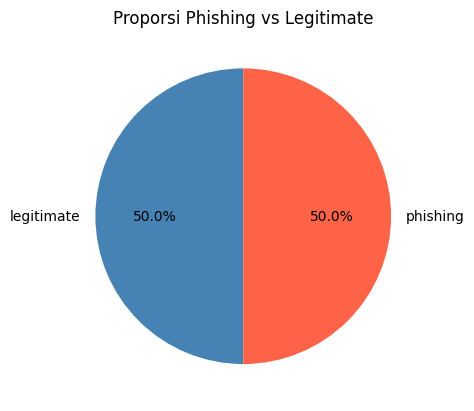

In [ ]:
print(df['status'].value_counts())
print(df['status'].value_counts(normalize=True) * 100)

df['status'].value_counts().plot(kind='pie', autopct='%1.1f%%',
    colors=['steelblue','tomato'], startangle=90)
plt.title('Proporsi Phishing vs Legitimate')
plt.ylabel('')
plt.show()

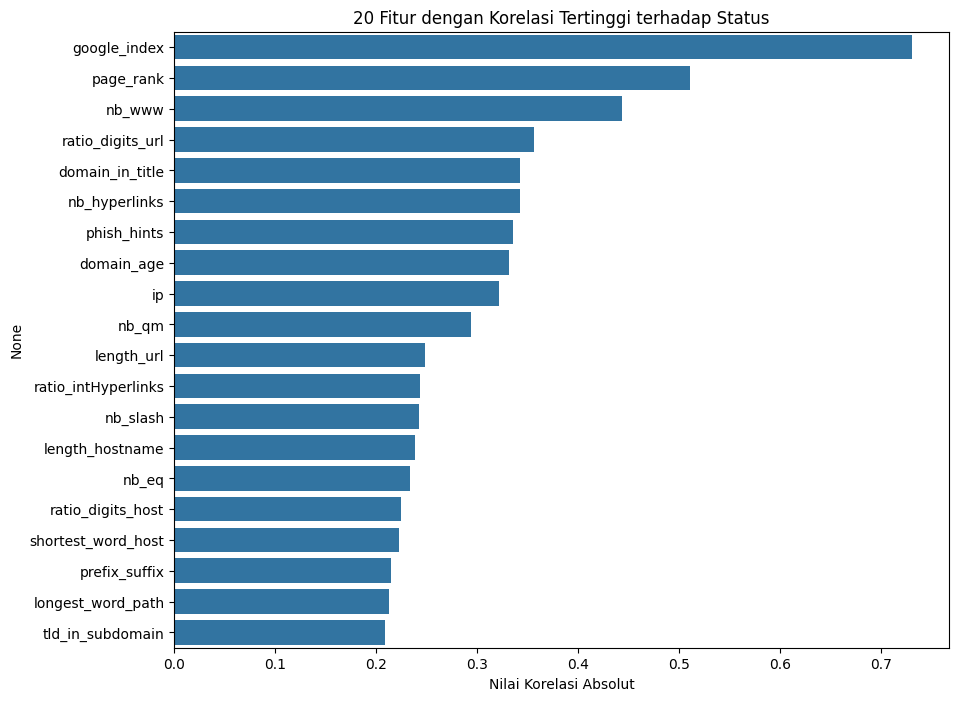

In [ ]:
df['status'] = df['status'].map({'legitimate': 0, 'phishing': 1})
corr = df.corr(numeric_only=True)['status'].abs().sort_values(ascending=False)

top20 = corr[1:21]

plt.figure(figsize=(10, 8))
sns.barplot(x=top20.values, y=top20.index)

plt.title('20 Fitur dengan Korelasi Tertinggi terhadap Status')
plt.xlabel('Nilai Korelasi Absolut')

plt.show()

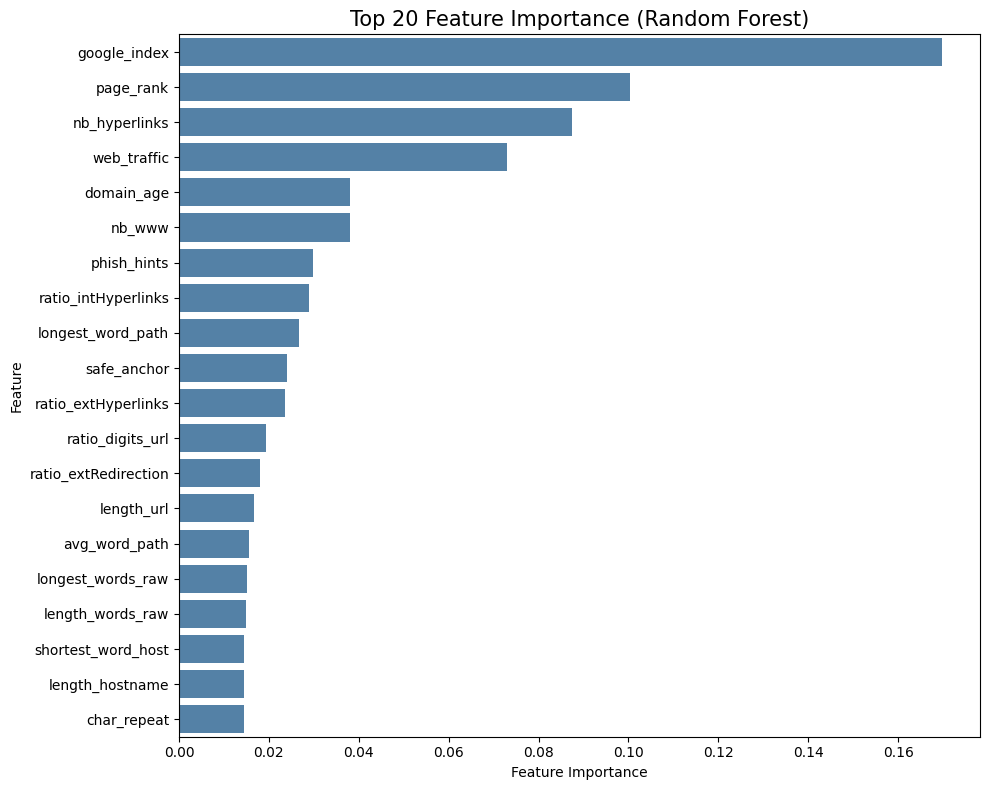

In [ ]:
from sklearn.ensemble import RandomForestClassifier
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("dataset_phishing.csv")

# Mengubah target menjadi numerik
df['status'] = df['status'].map({
    'legitimate': 0,
    'phishing': 1
})

# Memisahkan fitur dan target
X = df.drop(columns=['status', 'url'])
y = df['status']

# Membangun model Random Forest
rf = RandomForestClassifier(
    n_estimators=100,
    random_state=42
)

rf.fit(X, y)

# Mengambil nilai Feature Importance
importance = pd.DataFrame({
    'Feature': X.columns,
    'Importance': rf.feature_importances_
})

# Mengurutkan dan mengambil 20 fitur terbaik
top20 = importance.sort_values(
    by='Importance',
    ascending=False
).head(20)


# Visualisasi
plt.figure(figsize=(10,8))

sns.barplot(
    data=top20,
    x='Importance',
    y='Feature',
    color='steelblue'
)

plt.title('Top 20 Feature Importance (Random Forest)', fontsize=15)
plt.xlabel('Feature Importance')
plt.ylabel('Feature')

plt.tight_layout()
plt.show()

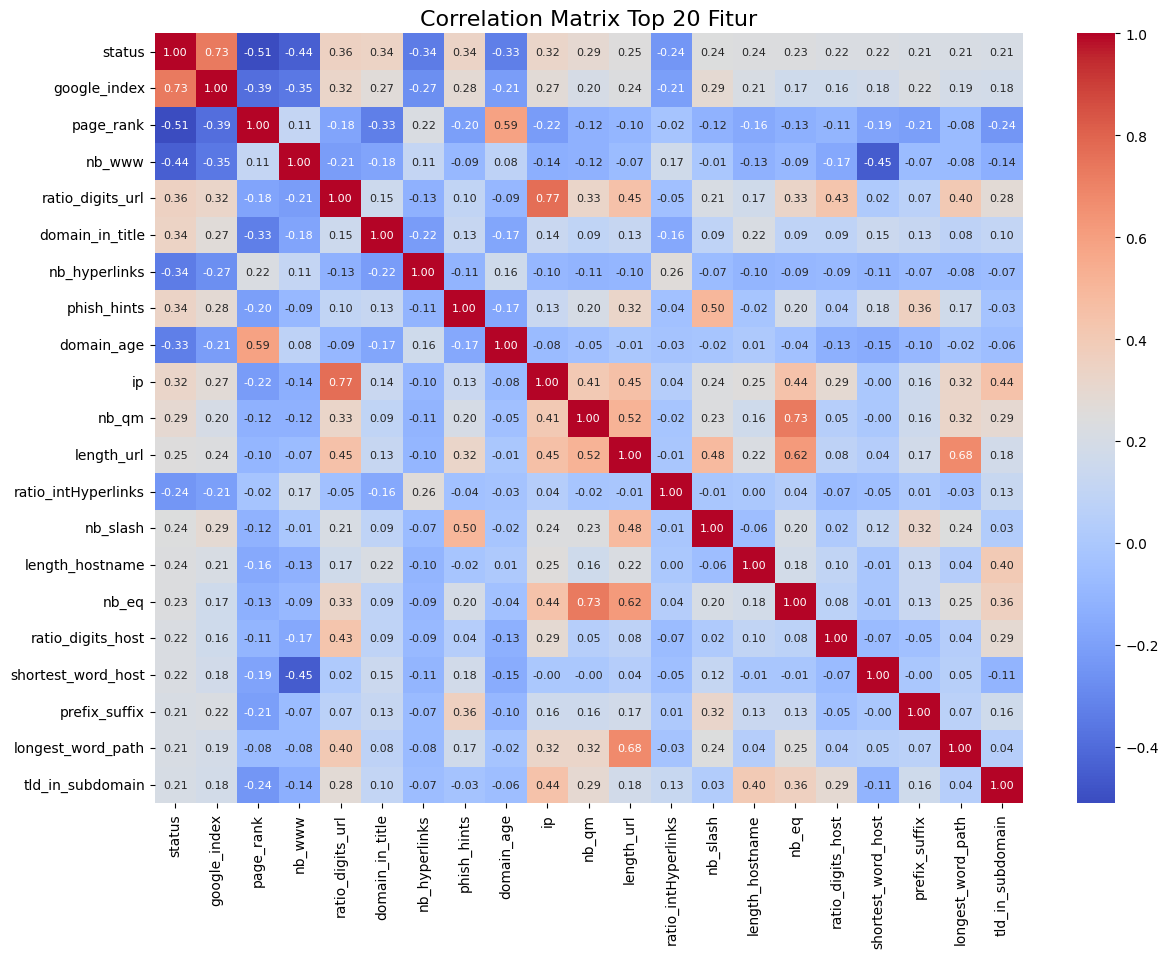

In [ ]:
corr = df.corr(numeric_only=True)['status'].abs().sort_values(ascending=False)

top_features = corr.index[:21]

plt.figure(figsize=(14, 10))
sns.heatmap(
    df[top_features].corr(),
    cmap='coolwarm',
    annot=True,
    fmt='.2f',
    annot_kws={'size': 8}
)

plt.title('Correlation Matrix Top 20 Fitur', fontsize=16)
plt.show()

In [ ]:
(df['domain_registration_length'] < 0).sum()

np.int64(46)

In [ ]:
df.groupby('status')['domain_registration_length'].apply(lambda x: (x == -1).sum())

,domain_registration_length
status,
0,32
1,14


In [ ]:
df.loc[df['domain_registration_length'] < 0, 'domain_registration_length'] = np.nan

df['domain_registration_length'] = df['domain_registration_length'].fillna(
    df['domain_registration_length'].median()
)

df.groupby('status')['domain_registration_length'].apply(lambda x: (x == -1).sum())

,domain_registration_length
status,
0,0
1,0


In [ ]:
(df['domain_age'] < 0).sum()

np.int64(1837)

In [ ]:
df[df['domain_age'] < 0]['domain_age'].value_counts()

,count
domain_age,
-1,1781
-2,55
-12,1


In [ ]:
df.groupby('status')['domain_age'].apply(lambda x: (x < 0).sum())

,domain_age
status,
0,843
1,994


In [ ]:
df.loc[df['domain_age'] < 0, 'domain_age'] = np.nan

df['domain_age'] = df['domain_age'].fillna(
    df['domain_age'].median()
)

df.groupby('status')['domain_age'].apply(lambda x: (x < -1).sum())

,domain_age
status,
0,0
1,0


=== INFORMASI DATA ===
Jumlah Fitur yang dipelajari: 87
Data Latih: 9144 baris
Data Uji: 2286 baris


=== MODEL : LOGISTIC REGRESSION ===
Akurasi Logistic Regression: 93.35%
Classification Report:
               precision    recall  f1-score   support

           0       0.93      0.93      0.93      1143
           1       0.93      0.93      0.93      1143

    accuracy                           0.93      2286
   macro avg       0.93      0.93      0.93      2286
weighted avg       0.93      0.93      0.93      2286



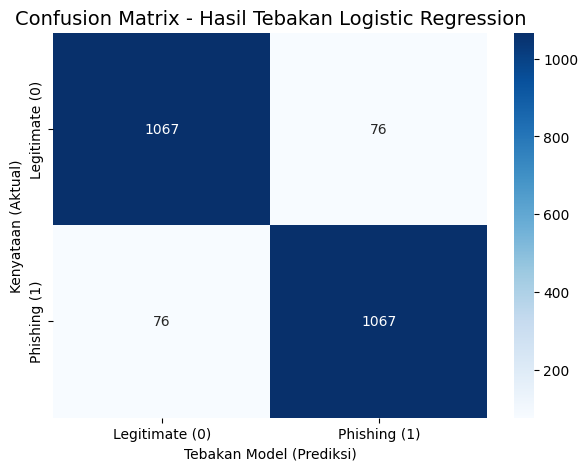

In [ ]:
X = df.drop(columns=['status']).select_dtypes(include='number')
y = df['status']

# Bagi data menjadi 80% Data Latih (Training) dan 20% Data Uji (Testing)
# stratify=y memastikan proporsi phishing & legitimate tetap seimbang saat dibagi
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

print("=== INFORMASI DATA ===")
print(f"Jumlah Fitur yang dipelajari: {X.shape[1]}")
print(f"Data Latih: {X_train.shape[0]} baris")
print(f"Data Uji: {X_test.shape[0]} baris\n")

# Lakukan Scaling (Sangat penting untuk Logistic Regression)
scaler = RobustScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)


print("\n=== MODEL : LOGISTIC REGRESSION ===")
# Logistic Regression sensitif terhadap skala, jadi wajib pakai X_train_scaled
lr_model = LogisticRegression(max_iter=1000, random_state=42)
lr_model.fit(X_train_scaled, y_train)
lr_pred = lr_model.predict(X_test_scaled)

print(f"Akurasi Logistic Regression: {accuracy_score(y_test, lr_pred) * 100:.2f}%")
print("Classification Report:\n", classification_report(y_test, lr_pred))


# --- 4. VISUALISASI CONFUSION MATRIX (Untuk Random Forest) ---
plt.figure(figsize=(7, 5))
cm = confusion_matrix(y_test, lr_pred)

# Membuat visualisasi Heatmap untuk tebakan benar vs salah
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=['Legitimate (0)', 'Phishing (1)'],
            yticklabels=['Legitimate (0)', 'Phishing (1)'])

plt.title('Confusion Matrix - Hasil Tebakan Logistic Regression', fontsize=14)
plt.ylabel('Kenyataan (Aktual)')
plt.xlabel('Tebakan Model (Prediksi)')
plt.show()

=== INFORMASI DATA ===
Jumlah Fitur yang dipelajari: 87
Data Latih: 9144 baris
Data Uji: 2286 baris

=== MODEL : LOGISTIC REGRESSION ===
Akurasi Logistic Regression: 92.65%
Classification Report:
               precision    recall  f1-score   support

           0       0.94      0.91      0.93      1143
           1       0.91      0.94      0.93      1143

    accuracy                           0.93      2286
   macro avg       0.93      0.93      0.93      2286
weighted avg       0.93      0.93      0.93      2286



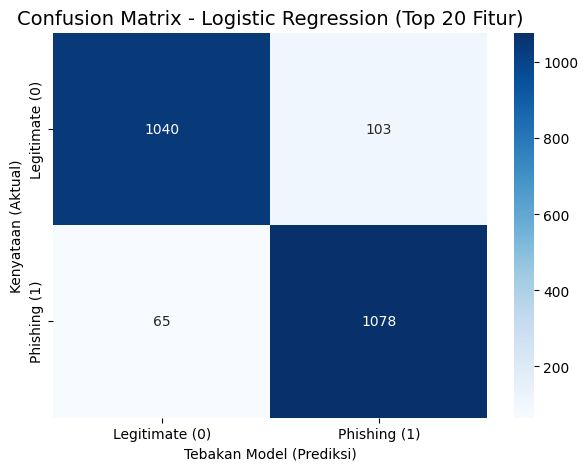


Interpretasi Confusion Matrix
-----------------------------
TP : 1078 Model memprediksi phishing dan memang phishing.
TN : 1040 Model memprediksi legitimate dan memang legitimate.
FP : 103 Model memprediksi phishing padahal sebenarnya legitimate.
FN : 65 Model memprediksi legitimate padahal sebenarnya phishing.



In [ ]:
X_all = df.drop(columns=['status']).select_dtypes(include='number')
y = df['status']

X_train, X_test, y_train, y_test = train_test_split(X_all, y, test_size=0.2, random_state=42, stratify=y)

# Pilih fitur dari train saja
corr_train = X_train.join(y_train).corr(numeric_only=True)['status'].abs().sort_values(ascending=False)
top_20_features = corr_train.drop('status').index[:20]

X_train = X_train[top_20_features]
X_test = X_test[top_20_features]

print("=== INFORMASI DATA ===")
print(f"Jumlah Fitur yang dipelajari: {X.shape[1]}")
print(f"Data Latih: {X_train.shape[0]} baris")
print(f"Data Uji: {X_test.shape[0]} baris\n")

# Lakukan Scaling (Sangat penting untuk Logistic Regression)
scaler = RobustScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)


# --- MODEL : LOGISTIC REGRESSION ---
print("=== MODEL : LOGISTIC REGRESSION ===")
lr_model = LogisticRegression(max_iter=1000, random_state=42)
lr_model.fit(X_train_scaled, y_train)
lr_pred = lr_model.predict(X_test_scaled)

print(f"Akurasi Logistic Regression: {accuracy_score(y_test, lr_pred) * 100:.2f}%")
print("Classification Report:\n", classification_report(y_test, lr_pred))


# --- 5. VISUALISASI CONFUSION MATRIX ---
plt.figure(figsize=(7, 5))
cm = confusion_matrix(y_test, lr_pred)

# Membuat visualisasi Heatmap untuk tebakan benar vs salah
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=['Legitimate (0)', 'Phishing (1)'],
            yticklabels=['Legitimate (0)', 'Phishing (1)'])

plt.title('Confusion Matrix - Logistic Regression (Top 20 Fitur)', fontsize=14)
plt.ylabel('Kenyataan (Aktual)')
plt.xlabel('Tebakan Model (Prediksi)')
plt.show()

# Ekstrak nilai dari confusion matrix
tn, fp, fn, tp = cm.ravel()

print(f"""
Interpretasi Confusion Matrix
-----------------------------
TP : {tp} Model memprediksi phishing dan memang phishing.
TN : {tn} Model memprediksi legitimate dan memang legitimate.
FP : {fp} Model memprediksi phishing padahal sebenarnya legitimate.
FN : {fn} Model memprediksi legitimate padahal sebenarnya phishing.
""")


Top 20 Feature Importance
                 Feature  Importance
85          google_index    0.190230
86             page_rank    0.103183
56         nb_hyperlinks    0.088487
83           web_traffic    0.069259
82            domain_age    0.039270
20                nb_www    0.038480
58   ratio_extHyperlinks    0.026475
46     longest_word_path    0.025237
50           phish_hints    0.024632
62  ratio_extRedirection    0.024009
74           safe_anchor    0.023792
57   ratio_intHyperlinks    0.023359
25      ratio_digits_url    0.019146
0             length_url    0.016843
1        length_hostname    0.016335
44     longest_words_raw    0.015434
39      length_words_raw    0.015028
40           char_repeat    0.013266
78       domain_in_title    0.012792
49         avg_word_path    0.012315

=== INFORMASI DATA ===
Jumlah fitur terpilih : 20
Data Latih : 9144
Data Uji : 2286

=== MODEL : LOGISTIC REGRESSION ===
Akurasi : 91.82%
              precision    recall  f1-score   support

  

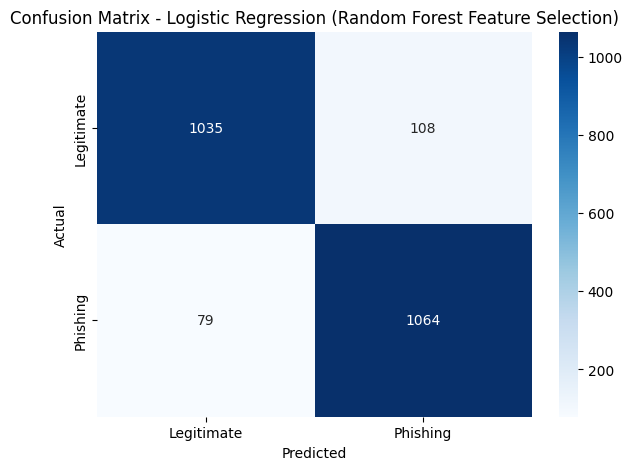


TP : 1064
TN : 1035
FP : 108
FN : 79



In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import RobustScaler
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns

# ============================
# 1. Memisahkan fitur & target
# ============================
X_all = df.drop(columns=['status']).select_dtypes(include='number')
y = df['status']

# ============================
# 2. Split Data
# ============================
X_train, X_test, y_train, y_test = train_test_split(
    X_all,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

# ============================
# 3. Feature Selection
#    Random Forest
# ============================
rf_selector = RandomForestClassifier(
    n_estimators=100,
    random_state=42
)

rf_selector.fit(X_train, y_train)

importance = pd.DataFrame({
    'Feature': X_train.columns,
    'Importance': rf_selector.feature_importances_
})

top20 = importance.sort_values(
    by='Importance',
    ascending=False
).head(20)

top_20_features = top20['Feature'].tolist()

print("\nTop 20 Feature Importance")
print(top20)

# Gunakan hanya 20 fitur terbaik
X_train = X_train[top_20_features]
X_test = X_test[top_20_features]

print("\n=== INFORMASI DATA ===")
print(f"Jumlah fitur terpilih : {len(top_20_features)}")
print(f"Data Latih : {X_train.shape[0]}")
print(f"Data Uji : {X_test.shape[0]}")

# ============================
# 4. Scaling
# ============================
scaler = RobustScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# ============================
# 5. Logistic Regression
# ============================
print("\n=== MODEL : LOGISTIC REGRESSION ===")

lr_model = LogisticRegression(
    max_iter=1000,
    random_state=42
)

lr_model.fit(X_train_scaled, y_train)

lr_pred = lr_model.predict(X_test_scaled)

print(f"Akurasi : {accuracy_score(y_test, lr_pred)*100:.2f}%")
print(classification_report(y_test, lr_pred))

# ============================
# 6. Confusion Matrix
# ============================
cm = confusion_matrix(y_test, lr_pred)

plt.figure(figsize=(7,5))

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=['Legitimate','Phishing'],
    yticklabels=['Legitimate','Phishing']
)

plt.title('Confusion Matrix - Logistic Regression (Random Forest Feature Selection)')
plt.xlabel('Predicted')
plt.ylabel('Actual')

plt.show()

tn, fp, fn, tp = cm.ravel()

print(f"""
TP : {tp}
TN : {tn}
FP : {fp}
FN : {fn}
""")